# Projeto de Classificação de Dados – 2026.2
## Parte 1 – Base Iris (2 pontos)
**Aluno:** Carlos José

**O que pede a atividade:** comparar pelo menos três classificadores na base Iris usando a matriz de confusão
e, para cada classe, a **sensibilidade**, a **precisão** e a **acurácia**. Isso é feito em três cenários:

| Cenário | Variáveis de entrada |
|---|---|
| A | as duas variáveis de maior correlação |
| B | as duas variáveis de maior correlação + PCA 1 |
| C | apenas PCA 1 e PCA 2 |

## 1. Bibliotecas

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_iris
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.metrics import confusion_matrix

# Classificadores vistos em aula
from sklearn.linear_model import LogisticRegression, Perceptron
from sklearn.tree import DecisionTreeClassifier
from sklearn.svm import SVC
from sklearn.neural_network import MLPClassifier

# Mesmo número usado na Parte 2 (soma das letras de "carlos")
SEMENTE = 68
np.random.seed(SEMENTE)

## 2. Carregando a base
150 flores, 50 de cada espécie, com 4 medidas em centímetros. Os nomes das colunas foram traduzidos.

In [2]:
iris = load_iris()

dados = pd.DataFrame(iris.data, columns=['comprimento_sepala', 'largura_sepala',
                                         'comprimento_petala', 'largura_petala'])
y = iris.target                      # 0 = setosa, 1 = versicolor, 2 = virginica
nomes_classes = list(iris.target_names)

dados['especie'] = [nomes_classes[i] for i in y]
dados.head()

,comprimento_sepala,largura_sepala,comprimento_petala,largura_petala,especie
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


In [3]:
# Resumo estatístico e quantidade de flores por espécie
display(dados.describe().round(2))
print(dados['especie'].value_counts())

,comprimento_sepala,largura_sepala,comprimento_petala,largura_petala
count,150.00,150.00,150.00,150.00
mean,5.84,3.06,3.76,1.20
std,0.83,0.44,1.77,0.76
min,4.30,2.00,1.00,0.10
25%,5.10,2.80,1.60,0.30
50%,5.80,3.00,4.35,1.30
75%,6.40,3.30,5.10,1.80
max,7.90,4.40,6.90,2.50


especie
setosa        50
versicolor    50
virginica     50
Name: count, dtype: int64


## 3. Correlação entre as variáveis
Procuramos o par de variáveis mais correlacionado entre si (cenários A e B).

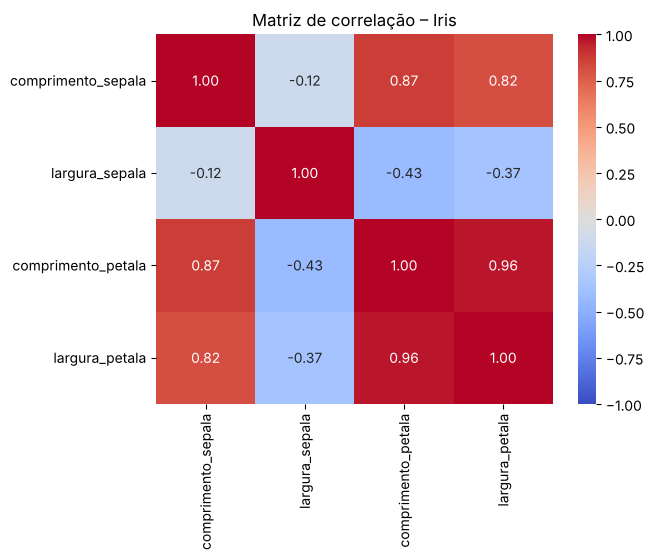

In [4]:
medidas = dados.drop(columns='especie')
correlacao = medidas.corr()

sns.heatmap(correlacao, vmin=-1, vmax=1, cmap='coolwarm', annot=True, fmt='.2f')
plt.title('Matriz de correlação – Iris')
plt.show()

In [5]:
# Procura automaticamente o par com maior correlação (em valor absoluto)
melhor_par, maior_valor = None, 0
colunas = list(correlacao.columns)
for i in range(len(colunas)):
    for j in range(i + 1, len(colunas)):
        valor = abs(correlacao.iloc[i, j])
        if valor > maior_valor:
            maior_valor = valor
            melhor_par = [colunas[i], colunas[j]]

print('Par de maior correlação:', melhor_par, '-> r =', round(maior_valor, 3))

# Conferência: correlação de cada medida com a espécie (0, 1, 2)
print('\nCorrelação com a espécie:')
print(medidas.corrwith(pd.Series(y)).round(3))

Par de maior correlação: ['comprimento_petala', 'largura_petala'] -> r = 0.963

Correlação com a espécie:
comprimento_sepala    0.783
largura_sepala       -0.427
comprimento_petala    0.949
largura_petala        0.957
dtype: float64


> As duas medidas da **pétala** são as mais correlacionadas entre si (r ≈ 0,96) e também as que mais
> acompanham a espécie. Elas formam o **cenário A**.

## 4. PCA (Análise de Componentes Principais)
Como na aula de PCA, aplicamos o PCA direto nas 4 medidas (todas em cm, mesma unidade).
O PCA cria novas variáveis (PCA 1, PCA 2...) que resumem os dados sem repetir informação.

In [6]:
pca = PCA(n_components=4)
componentes = pca.fit_transform(medidas)

dados['PCA1'] = componentes[:, 0]
dados['PCA2'] = componentes[:, 1]

print('Variação explicada por componente:', pca.explained_variance_ratio_.round(3))
print('PCA1 + PCA2 explicam:', round(pca.explained_variance_ratio_[:2].sum() * 100, 1), '% da variação')

# Peso de cada medida nos dois primeiros componentes
display(pd.DataFrame(pca.components_[:2], columns=medidas.columns, index=['PCA1', 'PCA2']).round(3))

Variação explicada por componente: [0.925 0.053 0.017 0.005]
PCA1 + PCA2 explicam: 97.8 % da variação


,comprimento_sepala,largura_sepala,comprimento_petala,largura_petala
PCA1,0.361,-0.085,0.857,0.358
PCA2,0.657,0.730,-0.173,-0.075


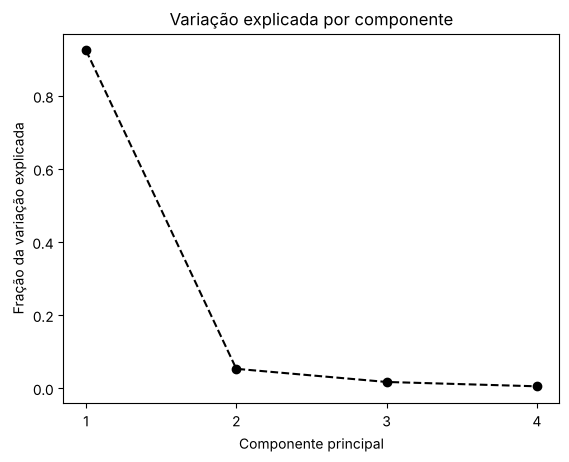

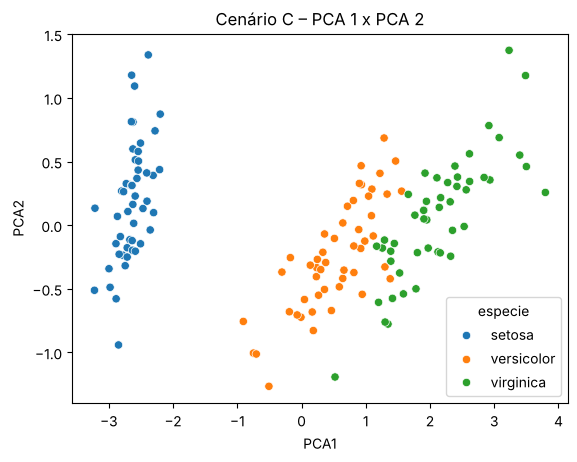

Correlação entre PCA1 e comprimento da pétala: 0.998


In [7]:
# Gráfico da variação explicada (scree plot)
plt.plot([1, 2, 3, 4], pca.explained_variance_ratio_, 'ko--')
plt.xticks([1, 2, 3, 4])
plt.xlabel('Componente principal')
plt.ylabel('Fração da variação explicada')
plt.title('Variação explicada por componente')
plt.show()

# Flores projetadas em PCA1 x PCA2
sns.scatterplot(data=dados, x='PCA1', y='PCA2', hue='especie')
plt.title('Cenário C – PCA 1 x PCA 2')
plt.show()

print('Correlação entre PCA1 e comprimento da pétala:',
      round(np.corrcoef(dados['PCA1'], dados['comprimento_petala'])[0, 1], 3))

## 5. Os três cenários

In [8]:
cenarios = {
    'A: 2 variáveis':        melhor_par,
    'B: 2 variáveis + PCA1': melhor_par + ['PCA1'],
    'C: PCA1 + PCA2':        ['PCA1', 'PCA2'],
}
for nome, cols in cenarios.items():
    print(nome, '->', cols)

A: 2 variáveis -> ['comprimento_petala', 'largura_petala']
B: 2 variáveis + PCA1 -> ['comprimento_petala', 'largura_petala', 'PCA1']
C: PCA1 + PCA2 -> ['PCA1', 'PCA2']


## 6. Classificadores
Cinco classificadores vistos em aula. Todos passam antes por uma **padronização** (média 0 e desvio 1),
feita dentro do `Pipeline` para que ela seja recalculada só com os dados de treino de cada rodada.

As redes usam a mesma configuração da aula de Redes Neurais.

In [9]:
def criar_classificadores():
    """Devolve um dicionário {nome: modelo} com padronização + classificador."""
    opcoes = {
        'Regressão Logística': LogisticRegression(max_iter=1000),
        'Árvore de Decisão':   DecisionTreeClassifier(max_depth=3, random_state=SEMENTE),
        'SVM':                 SVC(kernel='rbf', random_state=SEMENTE),
        'Perceptron':          Perceptron(max_iter=4000, eta0=0.001, random_state=SEMENTE),
        'Rede Neural MLP':     MLPClassifier(hidden_layer_sizes=(10, 10), activation='tanh',
                                             solver='sgd', max_iter=2000, random_state=SEMENTE),
    }
    return {nome: Pipeline([('padronizar', StandardScaler()), ('modelo', m)])
            for nome, m in opcoes.items()}

## 7. Como avaliamos
A base é pequena (20% de teste seriam só 30 flores). Por isso usamos **validação cruzada com 5 partes**
(`cross_val_predict`, como na aula de classificação): cada flor é prevista uma vez por um modelo que
**não a viu no treino**. Assim a matriz de confusão tem as 150 flores.

Para cada classe, ela é tratada como "positiva" e as outras como "negativas":
- **Sensibilidade** = VP / (VP + FN) → das flores dessa espécie, quantas o modelo acertou
- **Precisão** = VP / (VP + FP) → quando o modelo disse essa espécie, quantas vezes acertou
- **Acurácia da classe** = (VP + VN) / total

In [10]:
def metricas_por_classe(matriz, nomes):
    """Calcula precisão, sensibilidade e acurácia de cada classe a partir da matriz de confusão."""
    total = matriz.sum()
    linhas = []
    for i, nome in enumerate(nomes):
        VP = matriz[i, i]
        FN = matriz[i, :].sum() - VP     # era dessa classe, mas foi previsto como outra
        FP = matriz[:, i].sum() - VP     # foi previsto como essa classe, mas era outra
        VN = total - VP - FN - FP
        linhas.append({'classe': nome,
                       'precisao': VP / (VP + FP) if (VP + FP) > 0 else 0,
                       'sensibilidade': VP / (VP + FN),
                       'acuracia_classe': (VP + VN) / total})
    return pd.DataFrame(linhas)


divisao = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEMENTE)

## 8. Rodando todos os cenários e classificadores

In [11]:
resultados = []        # acurácia geral de cada combinação
tabelas_classe = {}    # métricas por classe de cada combinação
matrizes = {}          # matriz de confusão de cada combinação

for nome_cenario, colunas_cenario in cenarios.items():
    X = dados[colunas_cenario].values
    for nome_modelo, modelo in criar_classificadores().items():
        previsto = cross_val_predict(modelo, X, y, cv=divisao)
        matriz = confusion_matrix(y, previsto)

        matrizes[(nome_cenario, nome_modelo)] = matriz
        tabelas_classe[(nome_cenario, nome_modelo)] = metricas_por_classe(matriz, nomes_classes)
        resultados.append({'cenario': nome_cenario, 'classificador': nome_modelo,
                           'acuracia': np.trace(matriz) / matriz.sum(),
                           'erros': matriz.sum() - np.trace(matriz)})

resultados = pd.DataFrame(resultados)
print('Pronto!')

Pronto!


## 9. Resultados
### 9.1 Acurácia geral (entre parênteses: nº de erros em 150 flores)

classificador,Perceptron,Rede Neural MLP,Regressão Logística,SVM,Árvore de Decisão
cenario,,,,,
A: 2 variáveis,90.0% (15),95.3% (7),95.3% (7),95.3% (7),94.0% (9)
B: 2 variáveis + PCA1,90.7% (14),96.7% (5),95.3% (7),95.3% (7),94.7% (8)
C: PCA1 + PCA2,89.3% (16),97.3% (4),96.0% (6),96.0% (6),92.7% (11)


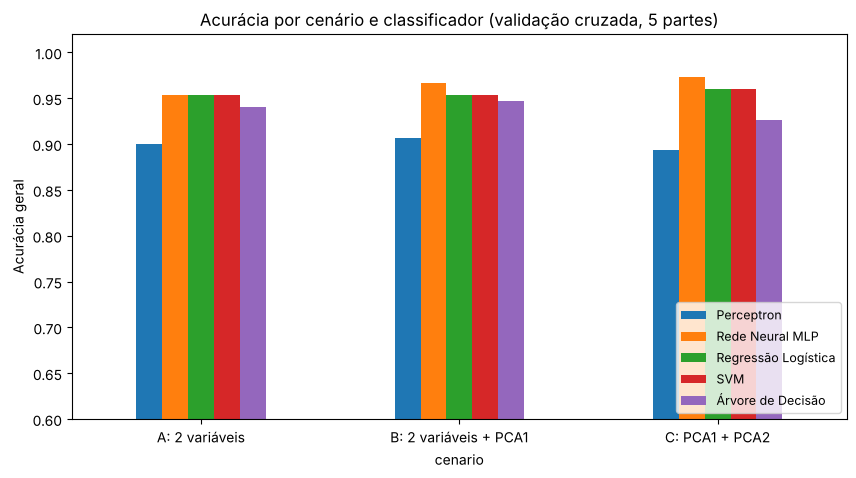

In [12]:
tabela = resultados.copy()
tabela['texto'] = (tabela['acuracia'] * 100).round(1).astype(str) + '% (' + tabela['erros'].astype(str) + ')'
display(tabela.pivot(index='cenario', columns='classificador', values='texto'))

# Gráfico de barras
resultados.pivot(index='cenario', columns='classificador', values='acuracia').plot(kind='bar', figsize=(10, 5))
plt.ylim(0.6, 1.02)
plt.ylabel('Acurácia geral')
plt.title('Acurácia por cenário e classificador (validação cruzada, 5 partes)')
plt.xticks(rotation=0)
plt.legend(loc='lower right', fontsize=9)
plt.show()

### 9.2 Matrizes de confusão (linhas: cenários A, B e C; colunas: classificadores)

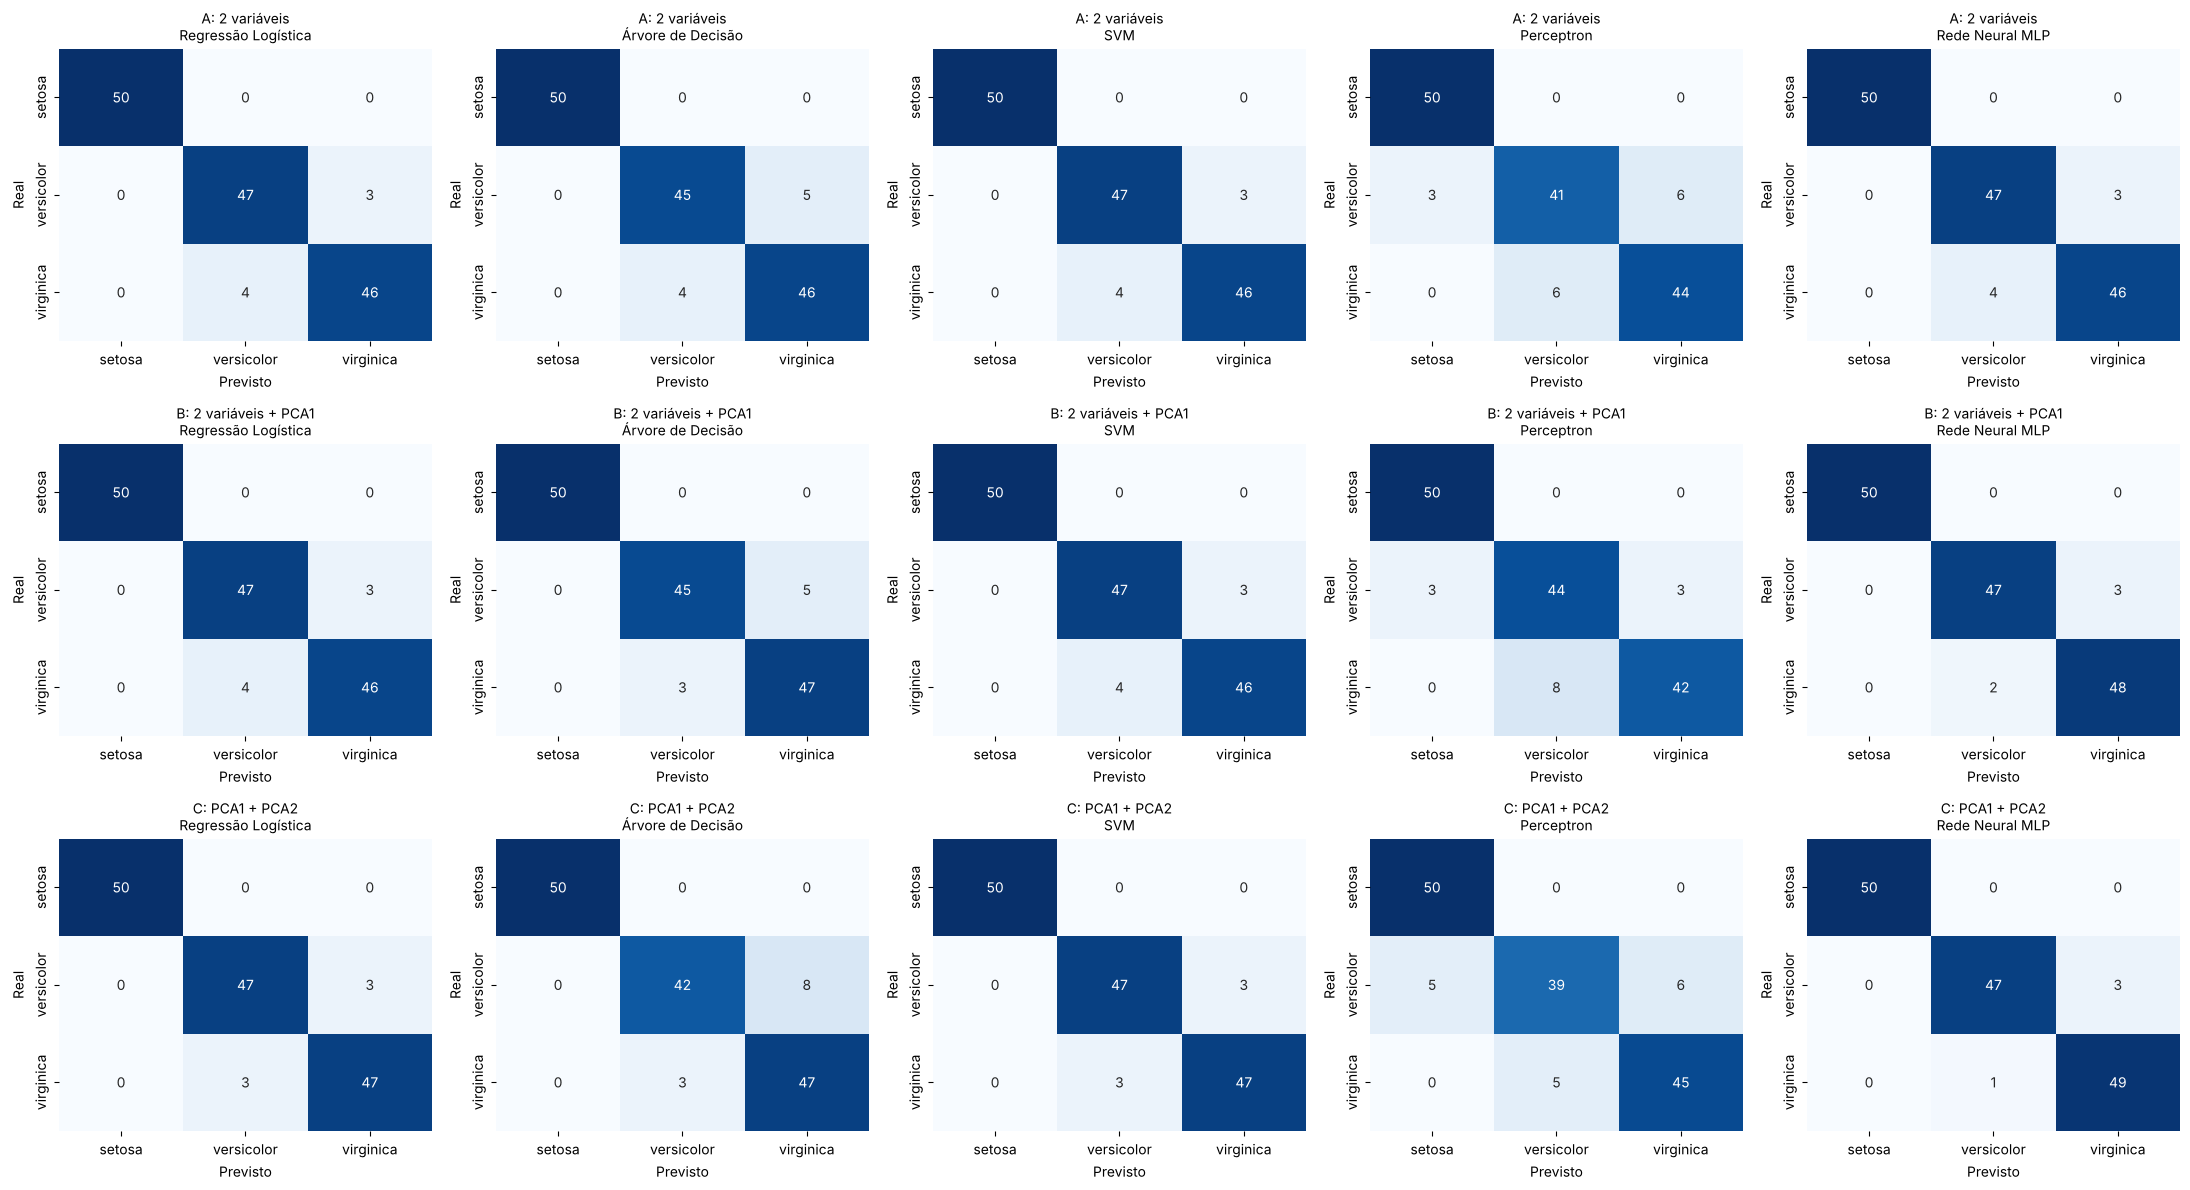

In [13]:
nomes_modelos = list(criar_classificadores().keys())
fig, eixos = plt.subplots(3, 5, figsize=(22, 12))

for i, nome_cenario in enumerate(cenarios):
    for j, nome_modelo in enumerate(nomes_modelos):
        sns.heatmap(matrizes[(nome_cenario, nome_modelo)], annot=True, fmt='d', cmap='Blues', cbar=False,
                    xticklabels=nomes_classes, yticklabels=nomes_classes, ax=eixos[i, j])
        eixos[i, j].set_title(f'{nome_cenario}\n{nome_modelo}', fontsize=10)
        eixos[i, j].set_xlabel('Previsto')
        eixos[i, j].set_ylabel('Real')

plt.tight_layout()
plt.show()

### 9.3 Precisão, sensibilidade e acurácia por classe (todas as combinações)

In [14]:
for (nome_cenario, nome_modelo), t in tabelas_classe.items():
    print(f'--- {nome_cenario} | {nome_modelo} ---')
    display(t.round(3))

--- A: 2 variáveis | Regressão Logística ---


,classe,precisao,sensibilidade,acuracia_classe
0,setosa,1.000,1.00,1.000
1,versicolor,0.922,0.94,0.953
2,virginica,0.939,0.92,0.953


--- A: 2 variáveis | Árvore de Decisão ---


,classe,precisao,sensibilidade,acuracia_classe
0,setosa,1.000,1.00,1.00
1,versicolor,0.918,0.90,0.94
2,virginica,0.902,0.92,0.94


--- A: 2 variáveis | SVM ---


,classe,precisao,sensibilidade,acuracia_classe
0,setosa,1.000,1.00,1.000
1,versicolor,0.922,0.94,0.953
2,virginica,0.939,0.92,0.953


... (20 outputs left out)

--- C: PCA1 + PCA2 | Perceptron ---


,classe,precisao,sensibilidade,acuracia_classe
0,setosa,0.909,1.00,0.967
1,versicolor,0.886,0.78,0.893
2,virginica,0.882,0.90,0.927


--- C: PCA1 + PCA2 | Rede Neural MLP ---


,classe,precisao,sensibilidade,acuracia_classe
0,setosa,1.000,1.00,1.000
1,versicolor,0.979,0.94,0.973
2,virginica,0.942,0.98,0.973


## 10. Melhor classificador

In [15]:
# Ordena pela acurácia; em caso de empate, pela menor sensibilidade entre as classes (o pior caso)
resultados['pior_sensibilidade'] = [tabelas_classe[(c, m)]['sensibilidade'].min()
                                    for c, m in zip(resultados['cenario'], resultados['classificador'])]
ranking = resultados.sort_values(['acuracia', 'pior_sensibilidade'], ascending=False)
display(ranking.head(5).round(3))

melhor = ranking.iloc[0]
print(f"Melhor combinação: {melhor['classificador']} no cenário {melhor['cenario']} "
      f"-> acurácia {melhor['acuracia']*100:.1f}% ({melhor['erros']} erros)")
display(tabelas_classe[(melhor['cenario'], melhor['classificador'])].round(3))

,cenario,classificador,acuracia,erros,pior_sensibilidade
14,C: PCA1 + PCA2,Rede Neural MLP,0.973,4,0.94
9,B: 2 variáveis + PCA1,Rede Neural MLP,0.967,5,0.94
10,C: PCA1 + PCA2,Regressão Logística,0.960,6,0.94
12,C: PCA1 + PCA2,SVM,0.960,6,0.94
0,A: 2 variáveis,Regressão Logística,0.953,7,0.92


Melhor combinação: Rede Neural MLP no cenário C: PCA1 + PCA2 -> acurácia 97.3% (4 erros)


,classe,precisao,sensibilidade,acuracia_classe
0,setosa,1.000,1.00,1.000
1,versicolor,0.979,0.94,0.973
2,virginica,0.942,0.98,0.973


## 11. Conclusões
- **Setosa** é sempre separada sem erro pelos bons modelos; os erros ficam entre **versicolor e virginica**,
  que se sobrepõem um pouco nas medidas da pétala.
- **Cenário A:** as duas medidas da pétala já resolvem bem o problema (cerca de 94% a 95%).
- **Cenário B:** acrescentar o PCA 1 ajuda pouco, porque o PCA 1 é quase igual ao comprimento da pétala
  (correlação ≈ 0,998), ou seja, é praticamente a mesma informação.
- **Cenário C:** PCA 1 e PCA 2 guardam cerca de 98% da variação e não repetem informação
  (o PCA 2 traz a sépala). Foi o melhor cenário para Regressão Logística, SVM e MLP.
  A Árvore piora aqui porque só faz cortes retos (paralelos aos eixos), e a divisão entre versicolor e
  virginica fica inclinada nesse plano.
- **Perceptron simples** foi o pior em todos os cenários: só traça fronteiras retas e não converge bem.
- **Melhor:** a **Rede Neural MLP no cenário C**, com a maior acurácia e precisão/sensibilidade
  altas nas três espécies (ver tabela acima).